In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import SGDClassifier  # Import SGDClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [2]:
# Constants
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [3]:
# Load the dataset
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    r'/home/smartcity_sp7/praveen/save_3_classes_data',
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE
)


Found 954 files belonging to 3 classes.


In [12]:
class_names = dataset.class_names
class_names

['AK', 'BCC', 'SK']

In [4]:
# Flatten the dataset
def flatten_dataset(dataset):
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')
            img_flattened = img_array.flatten()
            flat_data.append(img_flattened)
            target_data.append(label.numpy())
    return np.array(flat_data), np.array(target_data)

In [5]:
# Split the dataset
train_size = int(0.85 * len(dataset))
test_size = int(0.15 * len(dataset))

In [6]:
train_ds = dataset.take(train_size)
test_ds = dataset.skip(train_size).take(test_size)

In [7]:
x_train, y_train = flatten_dataset(train_ds)
x_test, y_test = flatten_dataset(test_ds)


In [8]:
# Creating and training an SGD classifier
sgd = SGDClassifier(max_iter=5000, random_state=72)  # Use SGDClassifier
sgd.fit(x_train, y_train)

SGDClassifier(alpha=0.0001, average=False, class_weight=None,
              early_stopping=False, epsilon=0.1, eta0=0.0, fit_intercept=True,
              l1_ratio=0.15, learning_rate='optimal', loss='hinge',
              max_iter=5000, n_iter_no_change=5, n_jobs=None, penalty='l2',
              power_t=0.5, random_state=72, shuffle=True, tol=0.001,
              validation_fraction=0.1, verbose=0, warm_start=False)

In [9]:
# Evaluate the model
y_pred = sgd.predict(x_test)

In [10]:
accuracy = accuracy_score(y_test, y_pred)
print("The model is {:.2f}% accurate".format(accuracy * 100))

The model is 82.03% accurate


In [13]:
from sklearn.metrics import classification_report

print("Validation metrics for Normal Random Forest:")
print(classification_report(y_true=y_test, y_pred=y_pred, target_names=class_names))

Validation metrics for Normal Random Forest:
              precision    recall  f1-score   support

          AK       0.77      0.95      0.85        39
         BCC       0.82      0.70      0.75        46
          SK       0.88      0.84      0.86        43

    accuracy                           0.82       128
   macro avg       0.82      0.83      0.82       128
weighted avg       0.82      0.82      0.82       128



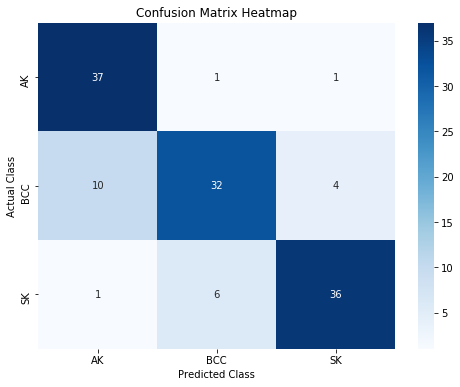

In [14]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, columns=class_names, index=class_names)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix Heatmap")
plt.show()

In [16]:
import joblib  # or use pickle

# Save the trained SVC model
joblib.dump(sgd, 'sgd_svm_save_weights.pkl')  

['sgd_svm_save_weights.pkl']